# Optimizing an SMA Crossover (Hourly BTC)


`optimize` runs a strategy once for every combination of parameter values
and reports the best one. This example tunes the two moving-average lengths
of the SMA crossover from `sma_cross.py`.

Steps:
1. Declare the parameters as class attributes.
2. Run a grid search and read the result.
3. Look at every combination tried, as a table and a heatmap.
4. Try a random search and a custom objective.
5. Inspect the winning strategy like any other backtest.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from overfitting import Strategy, optimize
from overfitting.indicators import sma, crossover, crossunder

df = pd.read_csv('./data/BTCUSDT.csv')
df['timestamp'] = pd.to_datetime(df['timestamp'], unit='ms')
df = df.set_index('timestamp').loc['2023-01-01':]
data = {"BTC": df}

**1. Parameters are class attributes.**

`fast = 20` and `slow = 50` are the defaults used when the strategy runs on
its own. `optimize` replaces them for each combination it tries. Read them
as `self.fast` and `self.slow`.

In [2]:
class SmaCross(Strategy):
    fast = 20
    slow = 50

    def init(self):
        self.set_leverage("BTC", 1)
        close = self.data["BTC"].close
        self.fast_ma = self.I(sma, close, self.fast)
        self.slow_ma = self.I(sma, close, self.slow)

    def next(self):
        position = self.get_position("BTC")
        if crossover(self.fast_ma, self.slow_ma) and position.qty == 0:
            price = self.price("BTC")
            self.limit_order("BTC", self.get_balance() // price, price)
        elif crossunder(self.fast_ma, self.slow_ma) and position.qty > 0:
            self.market_order("BTC", -position.qty)

**2. Grid search.**

Every combination of `fast` and `slow` is tried, except those the
`constraint` rejects (a fast average longer than the slow one makes no
sense). By default the search only sees the first 70% of the data; the last
30% is kept back to check the winner. Any `Strategy` argument, such as
`slippage` or `commission_rate`, can be passed and applies to every run.

In [3]:
result = optimize(
    SmaCross, data,
    params={"fast": range(5, 55, 5), "slow": range(20, 220, 20)},
    maximize="sharpe_ratio",
    constraint=lambda p: p.fast < p.slow,
    slippage=0.001,
)
print(result)

Optimization of SmaCross
  Trials            90 (grid)
  Maximized         sharpe_ratio
  Best parameters   fast=45, slow=100

                       Train (70%)    Test (30%)
  Total Return             136.55%         1.89%
  CAGR                     109.48%         3.80%
  Volatility                31.90%        32.36%
  Sharpe Ratio               2.476         0.274
  Sortino Ratio              5.087         0.442
  Max Drawdown             -14.39%       -15.80%
  Calmar Ratio               7.608         0.240
  Fills                        111            47

  The search only saw data before 2024-02-29. The test column is
  how these parameters did afterwards, on data that played no part in
  choosing them. The train column is the best of 90 tries, so expect
  it to be flattering.


The fields of the result:

In [4]:
print(result.best_params)   # the winning combination
print(result.trials)        # how many combinations were tried
print(result.split_time)    # where the test period starts
result.test                 # the winner's metrics on the held-out 30%

{'fast': 45, 'slow': 100}
90
2024-02-29 05:00:00


total_return      0.018859
cagr              0.037968
volatility        0.323615
sharpe_ratio      0.274361
sortino_ratio     0.442146
max_drawdown     -0.158046
calmar_ratio      0.240231
fills            47.000000
objective         0.274361
dtype: float64

**3. Every combination tried.**

`result.table` has one row per combination, best first, with its metrics on
the train period. `objective` is the value that was maximized.

In [5]:
result.table.head(10)

,fast,slow,total_return,cagr,volatility,sharpe_ratio,sortino_ratio,max_drawdown,calmar_ratio,fills,objective
0,45,100,1.365527,1.094778,0.318985,2.476324,5.086872,-0.143897,7.608078,111,2.476324
1,50,100,1.206942,0.973585,0.311849,2.334424,4.709740,-0.139411,6.983533,121,2.334424
2,35,140,1.183085,0.955248,0.309720,2.318306,4.597423,-0.133528,7.153925,81,2.318306
3,35,160,1.057443,0.858204,0.310355,2.149889,4.230618,-0.161810,5.303760,77,2.149889
4,40,100,1.078764,0.874730,0.316329,2.142664,4.384678,-0.173091,5.053589,119,2.142664
5,45,120,1.051733,0.853774,0.317575,2.100077,4.260736,-0.184170,4.635790,99,2.100077
6,30,140,1.086252,0.880528,0.327279,2.091607,3.971639,-0.175607,5.014207,89,2.091607
7,15,60,1.040993,0.845437,0.326272,2.038306,4.318226,-0.261345,3.234944,221,2.038306
8,40,140,0.984174,0.801227,0.317882,2.008248,3.885322,-0.167898,4.772093,81,2.008248
9,50,80,0.941208,0.767678,0.311299,1.983876,3.782953,-0.126608,6.063405,161,1.983876


`result.heatmap(x, y)` turns the table into a grid. A good parameter choice
sits in a broad area of good values; a lone bright cell surrounded by poor
ones is more likely luck than an edge.

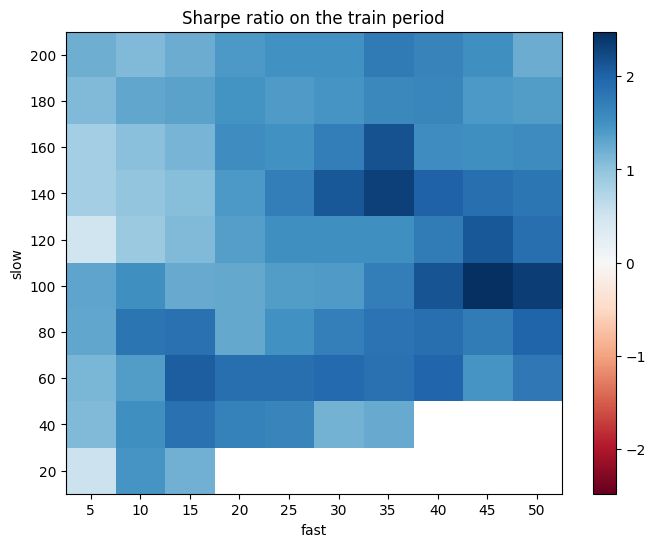

In [6]:
grid = result.heatmap("fast", "slow", metric="sharpe_ratio")

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(grid.values, cmap="RdBu", vmin=-abs(grid).max().max(),
                  vmax=abs(grid).max().max(), origin="lower", aspect="auto")
ax.set_xticks(range(len(grid.columns)), grid.columns)
ax.set_yticks(range(len(grid.index)), grid.index)
ax.set_xlabel("fast")
ax.set_ylabel("slow")
ax.set_title("Sharpe ratio on the train period")
fig.colorbar(image, ax=ax)
plt.show()

**4. Random search and a custom objective.**

With many parameters the grid grows fast. `method="random"` tries `n`
combinations picked at random (`seed` makes it repeatable).

`maximize` can also be a function of the metrics. Here: return per unit of
drawdown (CAGR divided by the maximum drawdown), but only for combinations
that traded at least 20 times.

In [7]:
def return_over_drawdown(m):
    if m["fills"] < 20:
        return None                     # never wins
    return m["cagr"] / abs(m["max_drawdown"])

random_result = optimize(
    SmaCross, data,
    params={"fast": range(5, 100), "slow": range(20, 400, 5)},
    constraint=lambda p: p.fast < p.slow,
    method="random", n=200, seed=42,
    maximize=return_over_drawdown,
    slippage=0.001,
)
print(random_result)

Optimization of SmaCross
  Trials            200 (random)
  Maximized         return_over_drawdown
  Best parameters   fast=62, slow=90

                       Train (70%)    Test (30%)
  Total Return             136.14%        18.51%
  CAGR                     109.16%        40.31%
  Volatility                30.97%        31.77%
  Sharpe Ratio               2.536         1.222
  Sortino Ratio              5.193         2.143
  Max Drawdown             -12.61%       -11.10%
  Calmar Ratio               8.655         3.632
  Fills                        143            57

  The search only saw data before 2024-02-29. The test column is
  how these parameters did afterwards, on data that played no part in
  choosing them. The train column is the best of 200 tries, so expect
  it to be flattering.


**5. The winning strategy.**

`result.strategy` is the winner, run over all the data (train and test) with
recording on, so the usual report, charts and trade tables work.

Performance Summary

Overview
  Start Date                                   2023-01-01 00:00
  End Date                                     2024-08-29 00:00
  Number of Years                                         1.663
  Initial Balance                                    100,000.00
  Final Balance                                      241,013.82
  Total Return                                          141.01%
  CAGR                                                   69.72%

Returns
  Best Day                                                9.16%
  Worst Day                                              -5.38%
  Best Month                                             32.41%
  Worst Month                                            -9.35%
  Positive Days                                          28.67%
  Positive Months                                        65.00%
  Average Up Day                                          1.83%
  Average Down Day                                       -1.08%
 

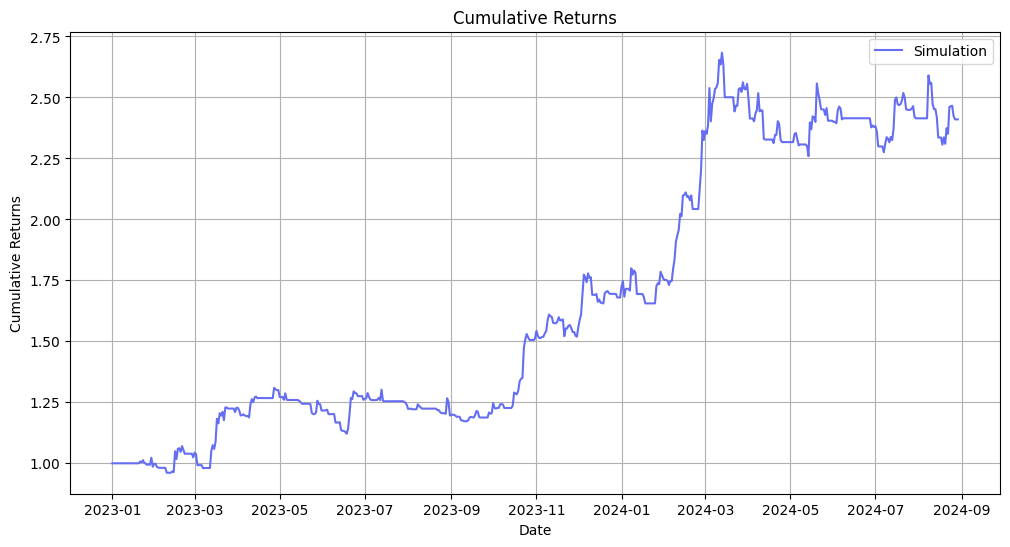

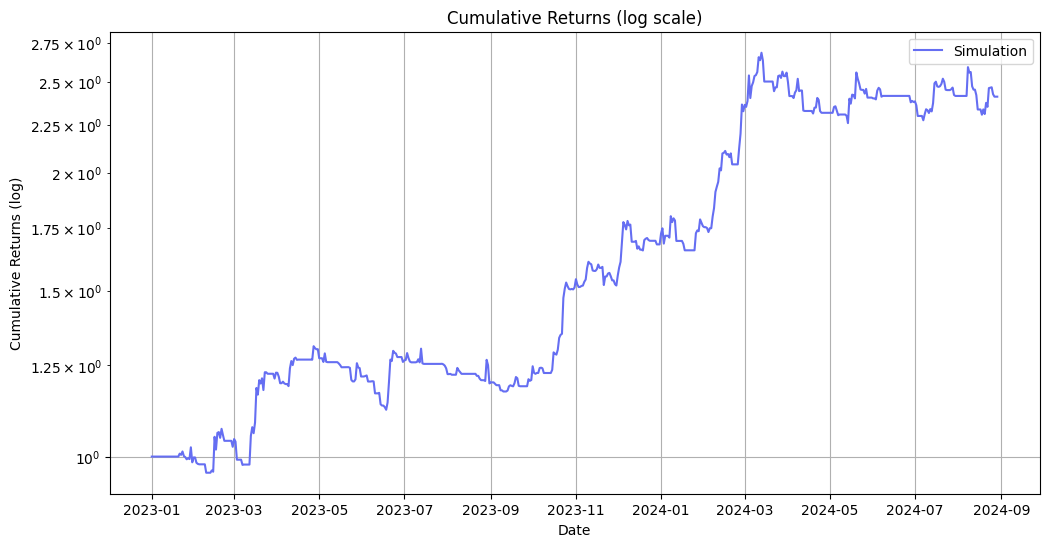

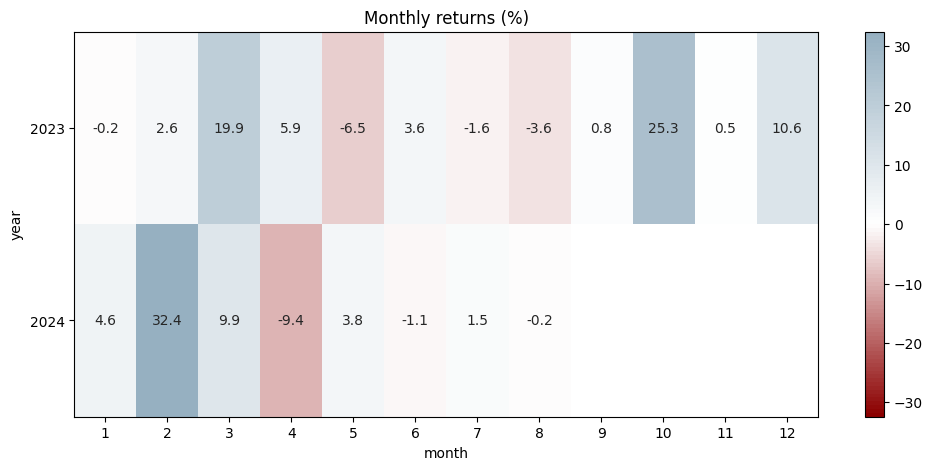

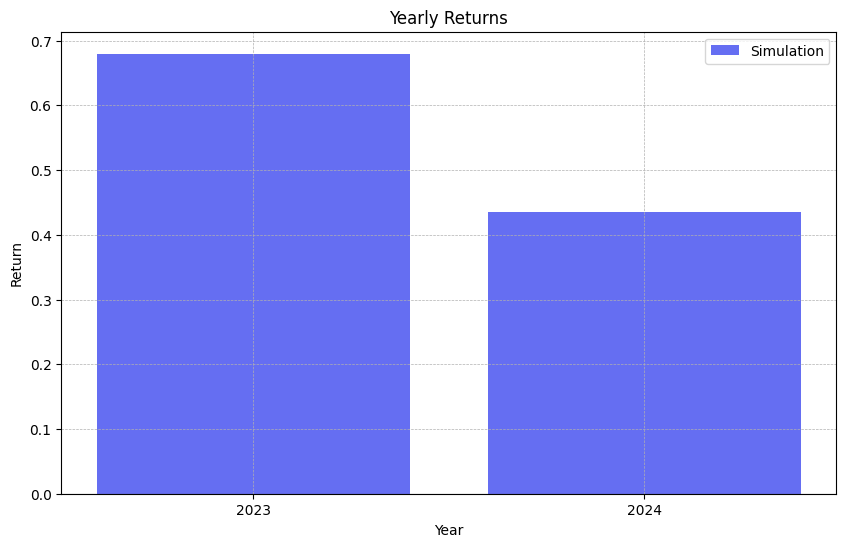

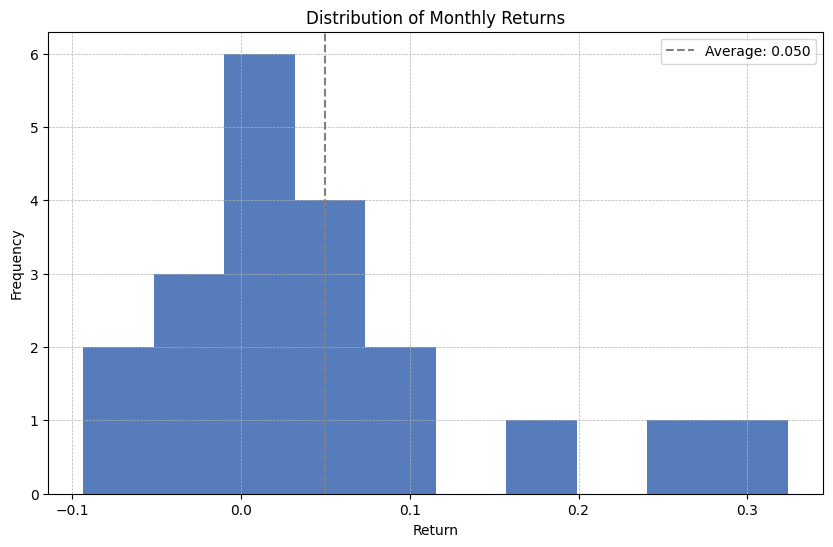

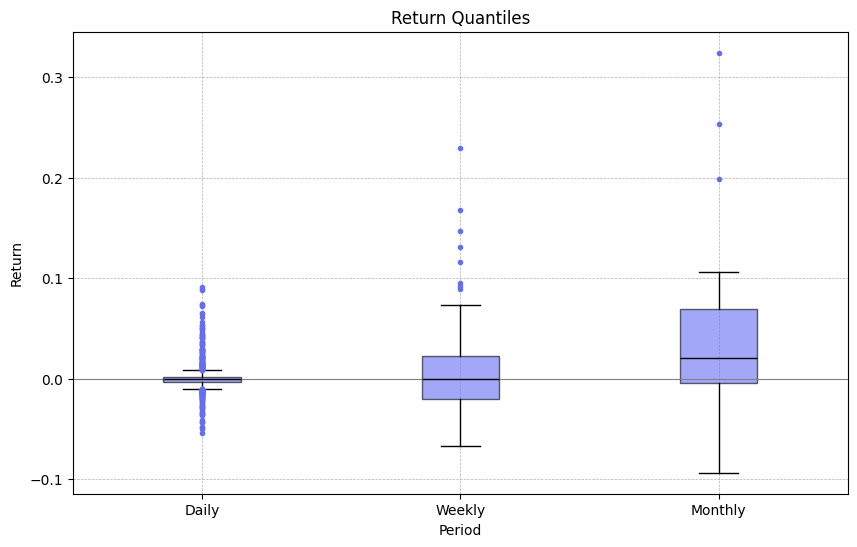

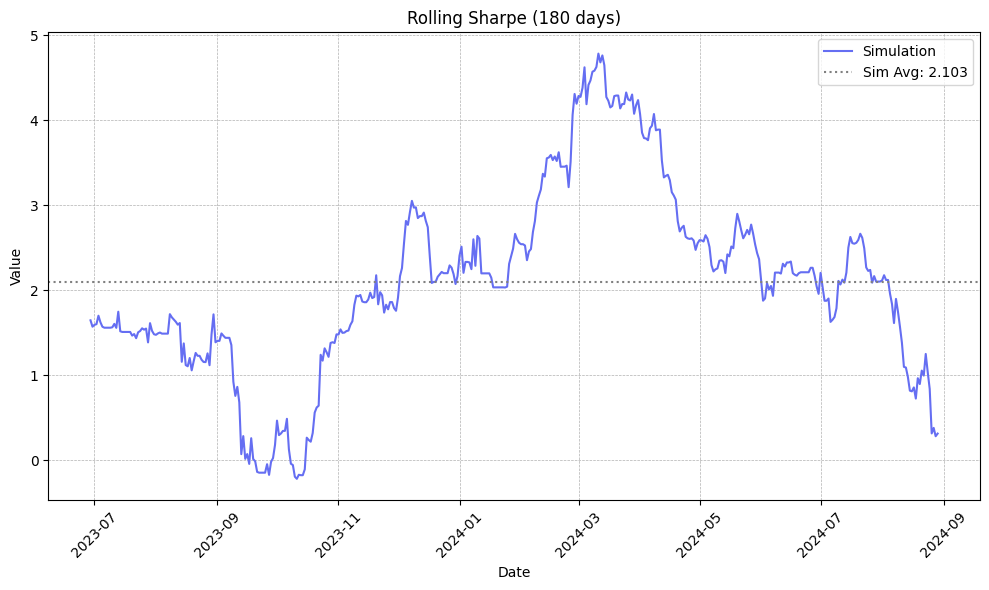

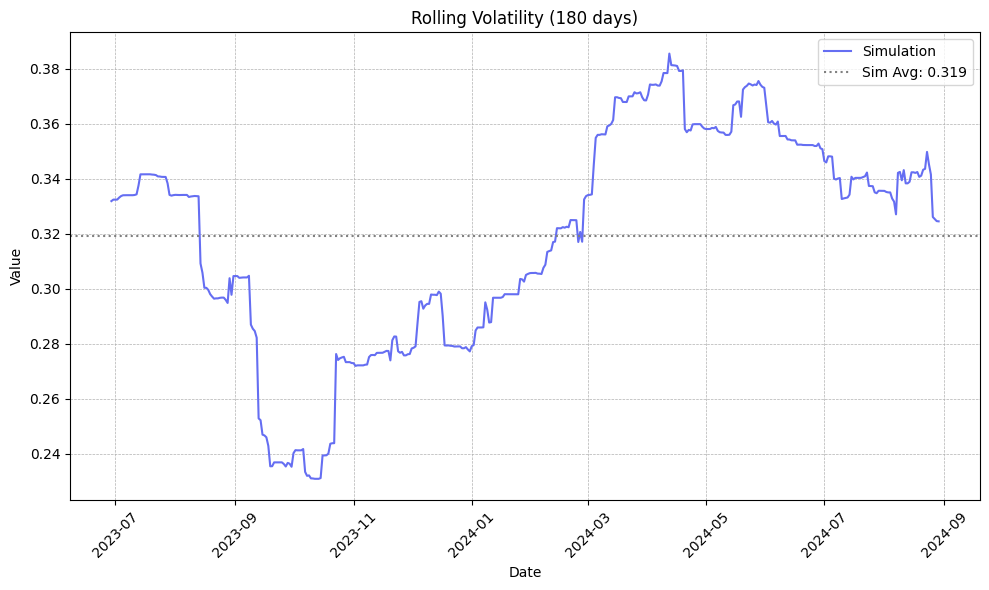

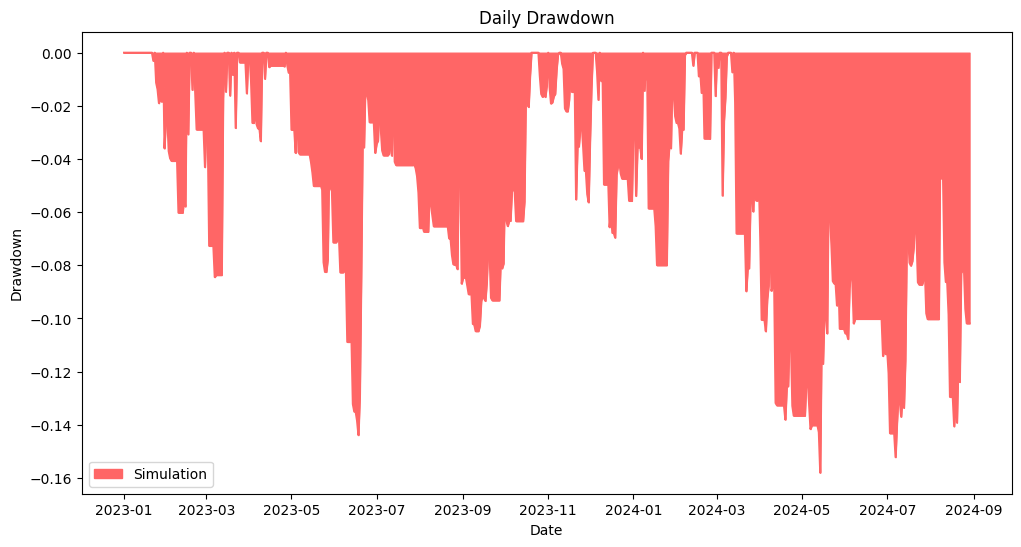

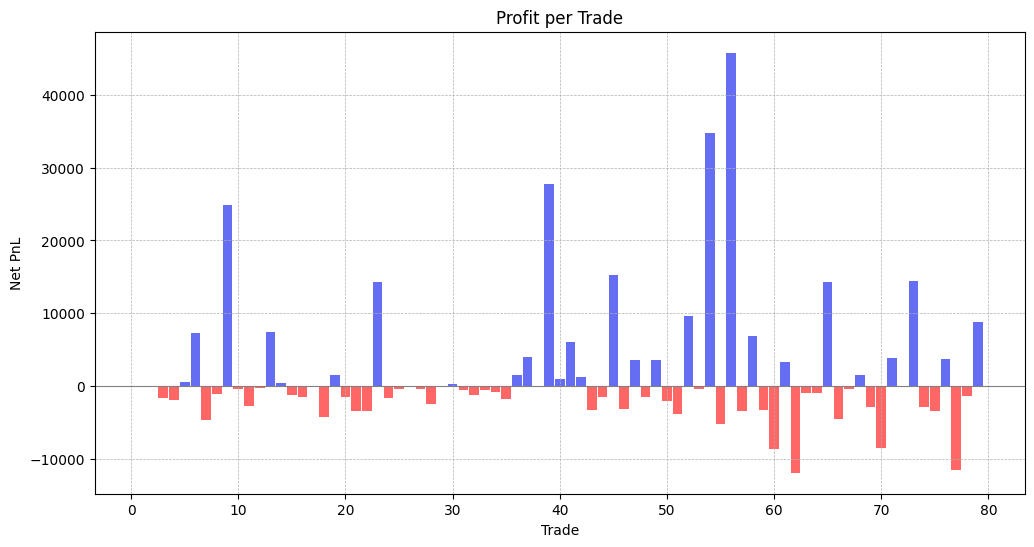

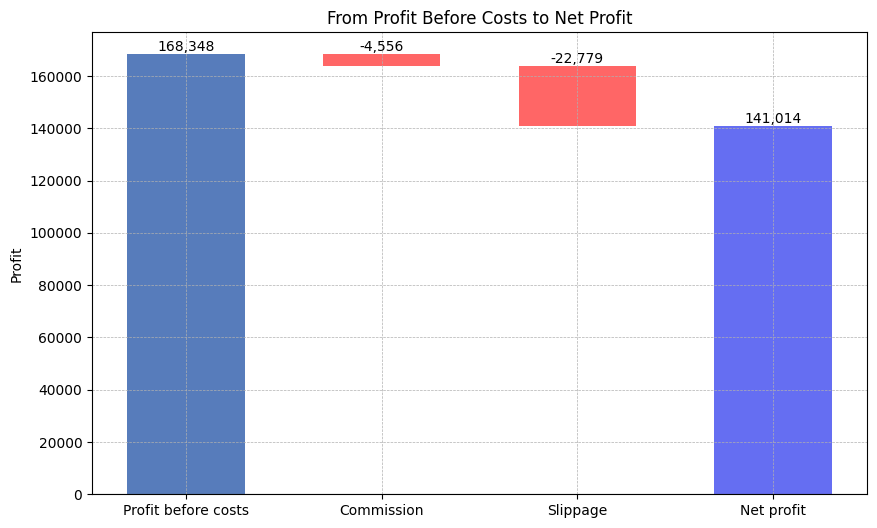

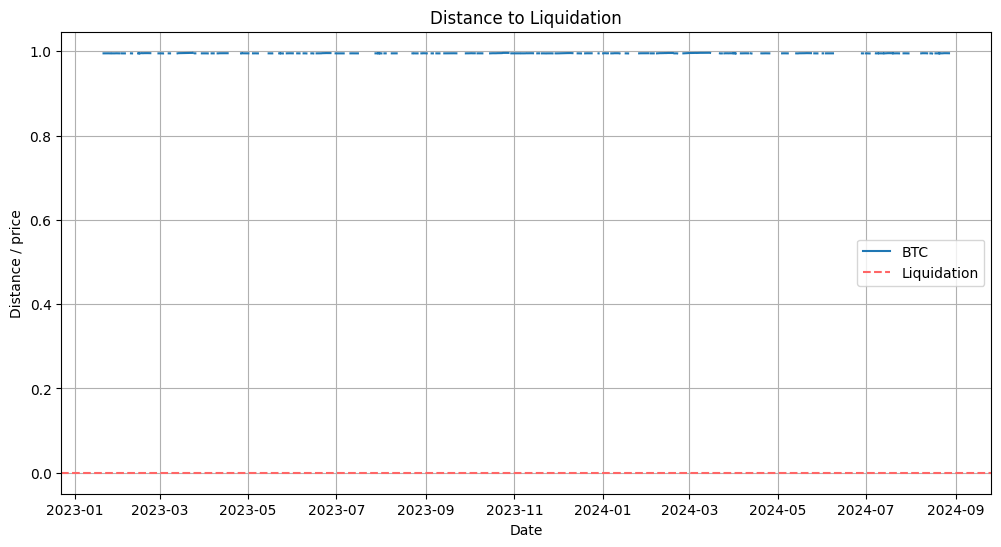

In [8]:
result.strategy.plot(result.returns)

In [9]:
result.strategy.fetch_round_trips().head()

,symbol,side,entry_time,exit_time,bars_held,duration,qty,entry_price,exit_price,pnl,commission,funding,net_pnl,return_pct,mae,mfe,fills,entry_label,exit_label,is_liquidation
0,BTC,LONG,2023-01-21 01:00:00,2023-01-25 14:00:00,109,4 days 13:00:00,4.0,22593.9714,22569.0084,-99.8520,36.130384,0.0,-135.982384,-0.001505,-0.013586,0.035232,2,None,None,False
1,BTC,LONG,2023-01-26 21:00:00,2023-01-31 18:00:00,117,4 days 21:00:00,4.0,23129.0059,23120.1567,-35.3968,36.999330,0.0,-72.396130,-0.000783,-0.027879,0.036045,2,None,None,False
2,BTC,LONG,2023-02-02 08:00:00,2023-02-04 20:00:00,60,2 days 12:00:00,4.0,23810.7870,23403.9726,-1627.2576,37.771808,0.0,-1665.029408,-0.017482,-0.025610,0.014204,2,None,None,False
3,BTC,LONG,2023-02-09 00:00:00,2023-02-09 19:00:00,19,0 days 19:00:00,4.0,22978.8559,22489.4880,-1957.4716,36.374675,0.0,-1993.846275,-0.021692,-0.027754,0.001260,2,None,None,False
4,BTC,LONG,2023-02-13 22:00:00,2023-02-14 12:00:00,14,0 days 14:00:00,4.0,21625.7041,21777.1011,605.5880,34.722244,0.0,570.865756,0.006599,-0.001494,0.011759,2,None,None,False
